# Analysis 1 — Treasury Market Conditions and Scenarios

## Setup — FRED observations

In [1]:
from pathlib import Path
from bondview.data.fred import FredDataManager
from bondview.presentation.widgets import DateRangePicker
from bondview import TreasuryMarketAnalysis

In [2]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SNAPSHOT_DIR = PROJECT_ROOT / "data/fred"
fred = FredDataManager(SNAPSHOT_DIR, env_path=PROJECT_ROOT / ".env")

### Donwload

In [ ]:
FRED_SERIES = (
    "DGS2", "DGS10", "DGS30",
    "THREEFY2", "THREEFYTP2", "THREEFY10", "THREEFYTP10",
)
start = None
end = None
downloaded = fred.download(series_ids=FRED_SERIES, start=start, end=end)

In [ ]:
# Optional inspection; downloaded is also a DataFrame.
#fred.report(series_ids='DGS10')  
fred.report()

In [ ]:
fred.save()

### Load Treasury observations

Required data setup for A and C; no KW inputs are needed.

In [3]:
observations = fred.load(series_ids=["DGS2", "DGS10", "DGS30"])
fred.report()
market = TreasuryMarketAnalysis(observations)

FRED observations (file)
Series ID             Nonmissing
DGS2                     12,597
DGS10                    16,189
DGS30                    12,419
Complete shared observations: 12,419


## A. Yield-curve conditions and movements

Examine 2Y, 10Y, and 30Y Treasury yields and compare available observations within the selected date range.

### Treasury yield history

Plot historical 2Y, 10Y, and 30Y Treasury yields over the selected date range.

In [4]:
date_range = DateRangePicker(observations)

In [8]:
date_range

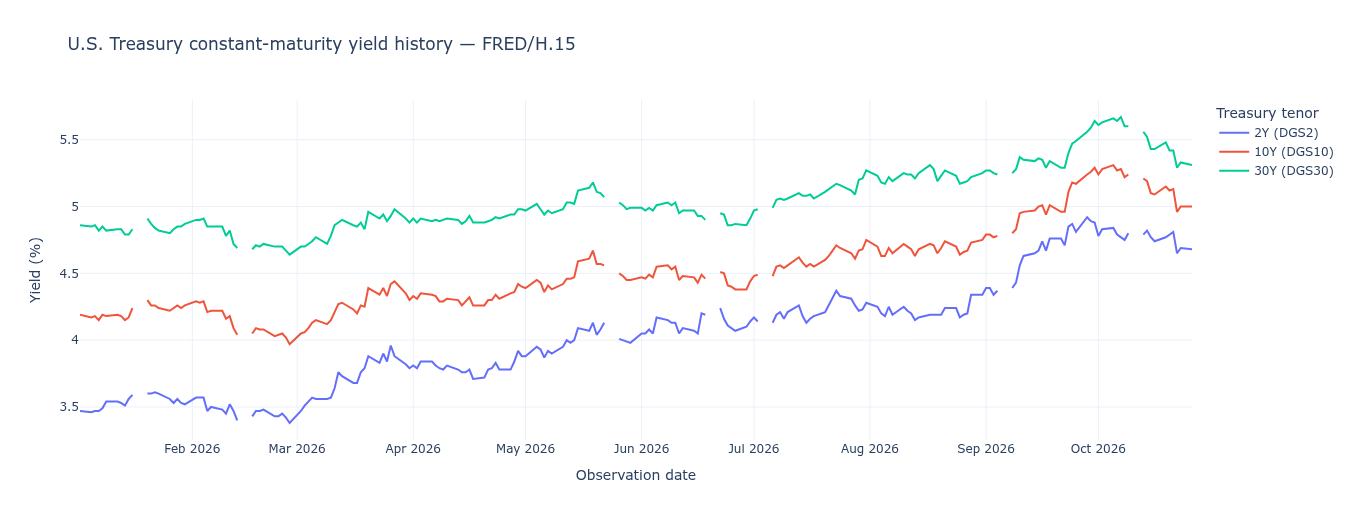

In [9]:
history_figure = market.show_history(*date_range.get_dates())

### Treasury yield and curve movements

Calculate yield and spread changes between selected dates, classify curve movements, and display the results

In [10]:
curve = market.curve(
    *date_range.get_dates(),
    yield_change_tolerance_bp=5,
    slope_tolerance_bp=5,
)
curve.show()

,2026-01-02,2026-10-26,Change,Curve configuration,Movement / regime
Treasury measure,,,,,
2Y yield,3.47%,4.68%,+121 bp,—,Yield rose
10Y yield,4.19%,5.00%,+81 bp,—,Yield rose
30Y yield,4.86%,5.31%,+45 bp,—,Yield rose
10Y−2Y spread,+72 bp,+32 bp,-40 bp,Upward-sloping → Upward-sloping,Bear flattening
30Y−10Y spread,+67 bp,+31 bp,-36 bp,Upward-sloping → Upward-sloping,Bear flattening


Greatest upward yield movement among available tenors: 2Y (+121 bp). 10Y−2Y spread: Bear flattening. 30Y−10Y spread: Bear flattening. These are net endpoint movements, not the full path or a forecast.

## B. Expected short rates and term premiums

*Load KW model estimates*

In [11]:
kw_observations = fred.load(
    series_ids=["THREEFY2", "THREEFYTP2", "THREEFY10", "THREEFYTP10"]
)

### 2Y and 10Y yield decomposition

In [12]:
kw_date_range = DateRangePicker(kw_observations)

In [13]:
kw_date_range

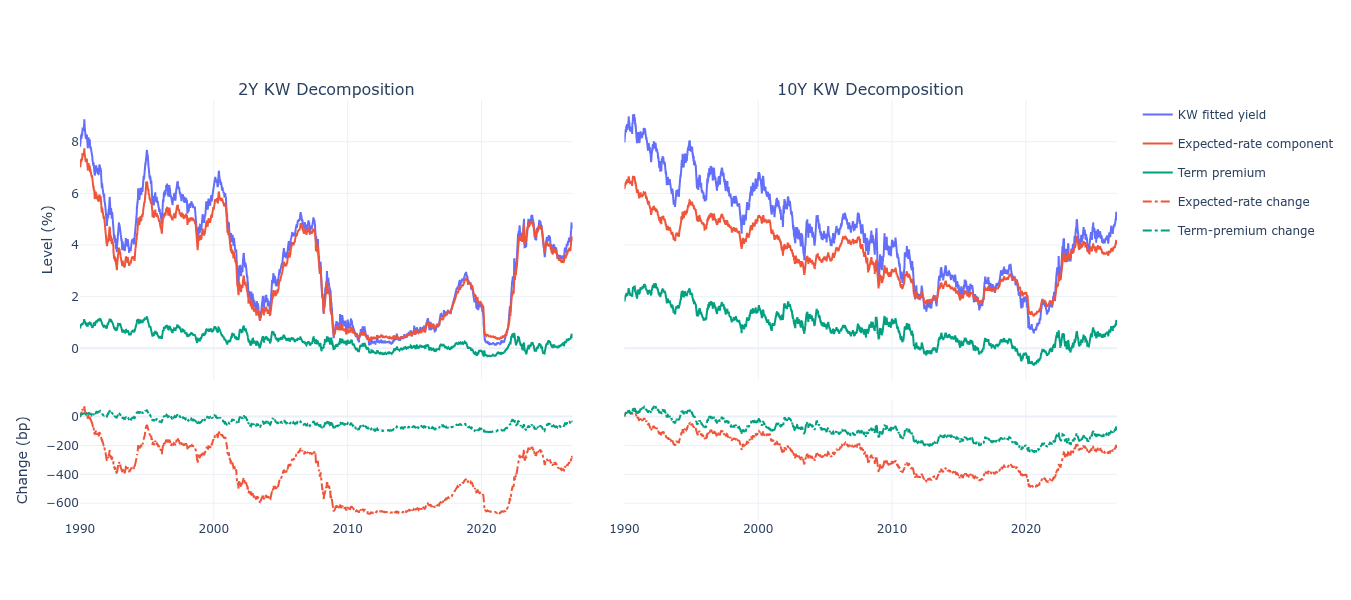

In [14]:
decomposition = market.decomposition(kw_observations, *kw_date_range.get_dates())
decomposition_figure = decomposition.show(width=1300, height=600)

## C. Conditional joint yield movements

Run Setup (load Treasury observations) and this section independently of A/B. Select whole historical intervals matching an inclusive 2Y or 10Y change range.

In [15]:
condition_tenor = "DGS10"
lower_bp, upper_bp = -25, 25
horizon_months = 6
sampling = "monthly"  # Or "daily"
reference_start = None  # Earliest complete common observation
reference_end = None    # Latest complete common observation

### Complete scenario set

Monthly intended ends move backward by one calendar month from the latest complete observation, always offset from that original anchor. Daily intended ends use every complete date, newest first. Subtract the calendar-month horizon from each intended end and select the first and last complete observations inside the inclusive window. Stop before intended starts precede complete reference history. Skip windows with fewer than two observations or more than seven days of combined endpoint shortfall. No outside-window searching or yield filling is used. Actual/intended dates, elapsed days and shortfall remain available for audit.

In [21]:
scenarios = market.scenarios(
    condition_tenor=condition_tenor,
    lower_bp=lower_bp, upper_bp=upper_bp,
    horizon_months=horizon_months, sampling=sampling,
    reference_start=reference_start, reference_end=reference_end,
)
joint_scenarios = scenarios.scenarios
joint_scenarios

,scenario_id,start_date,target_end_date,end_date,elapsed_days,DGS2_change_bp,DGS10_change_bp,DGS30_change_bp,target_start_date,shortfall_days
0,UST_20251226_20260626,2025-12-26,2026-06-26,2026-06-26,182,61.0,24.0,6.0,2025-12-26,0
1,UST_20250926_20260326,2025-09-26,2026-03-26,2026-03-26,181,33.0,22.0,16.0,2025-09-26,0
2,UST_20250826_20260226,2025-08-26,2026-02-26,2026-02-26,184,-19.0,-24.0,-23.0,2025-08-26,0
3,UST_20250728_20260126,2025-07-28,2026-01-26,2026-01-26,182,-35.0,-20.0,-16.0,2025-07-26,2
4,UST_20250626_20251226,2025-06-26,2025-12-26,2025-12-26,183,-24.0,-12.0,0.0,2025-06-26,0
...,...,...,...,...,...,...,...,...,...,...
157,UST_19781127_19790525,1978-11-27,1979-05-26,1979-05-25,179,-10.0,15.0,25.0,1978-11-26,2
158,UST_19770526_19771125,1977-05-26,1977-11-26,1977-11-25,183,86.0,10.0,6.0,1977-05-26,1
159,UST_19770426_19771026,1977-04-26,1977-10-26,1977-10-26,183,117.0,19.0,7.0,1977-04-26,0
160,UST_19770328_19770926,1977-03-28,1977-09-26,1977-09-26,182,78.0,-5.0,-10.0,1977-03-26,2


### Descriptive statistical summary

Marginal quantiles summarize the set; they do not form additional joint scenarios. Overlapping-window counts are descriptive, not independent event frequencies or forecast probabilities.

In [23]:
scenarios.show_summary()

Condition: 10Y change [-25, 25] bp (inclusive). Horizon: 6 calendar months; monthly end anchors. Complete reference history: 1977-02-15 to 2026-10-26. Selected scenarios: 162 / 591 eligible windows.

,Minimum (bp),P10 (bp),Median (bp),P90 (bp),Maximum (bp)
Treasury tenor,,,,,
2Y,-155.0,-51.9,-0.5,53.6,117.0
10Y,-25.0,-21.0,-4.0,19.0,24.0
30Y,-49.0,-28.8,-4.0,25.9,56.0


Statistics are in bp. Overlapping intervals and marginal quantiles are descriptive, not independent event frequencies or forecast probabilities. Monthly windows move backward from the latest complete date; daily ends use every complete date, newest first. Endpoints are the first and last complete observations inside each intended calendar-month window. Windows with fewer than two observations or over seven days of combined endpoint shortfall are excluded.

,Minimum (bp),P10 (bp),Median (bp),P90 (bp),Maximum (bp)
Treasury tenor,,,,,
2Y,-155.0,-51.9,-0.5,53.6,117.0
10Y,-25.0,-21.0,-4.0,19.0,24.0
30Y,-49.0,-28.8,-4.0,25.9,56.0


### Joint yield changes

Color identifies the conditioning tenor. Hover retains historical interval dates and elapsed days.

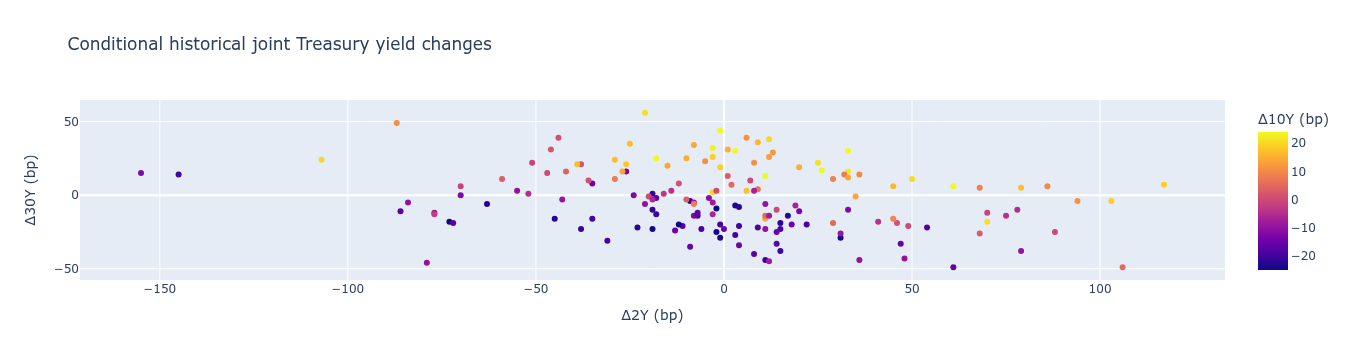

In [19]:
scenario_figure = scenarios.show_plot()